# 05 - LightGCN ablation study

**Owner:** Member 4
**Task:** Starting from the best setting of notebook 04, change one component at a time: mean vs. last-layer combination, symmetric vs. no normalization, edge dropout on/off. 3 seeds. Table and figure of the deltas on both datasets and both tests (biased and unbiased).
**Inputs:** `experiments.run_grid.SELECTED` and `ABLATIONS`; the baseline runs of notebook 06 (`results/06_main_comparison_<dataset>*.json`)
**Outputs:** results/05_ablation_<dataset>.json (every run), results/05_ablation.json (tables), results/05_ablation.png

After running: save the numbers to `results/`, append an entry to `LOG.md`, and write the matching report section.

In [1]:
import os, sys, json
sys.path.insert(0, os.path.abspath(os.path.join(os.getcwd(), "..", "src")))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import data
import models
import training
import inference

SEEDS = [0, 1, 2]
RESULTS_DIR = os.path.abspath(os.path.join(os.getcwd(), "..", "results"))
os.makedirs(RESULTS_DIR, exist_ok=True)


## Experiments

### Variants

The baseline is the selected LightGCN of notebook 04 (3 layers, dim 128, lr 1e-3, L2 1e-4, layer mean, symmetric normalisation $D^{-1/2} A D^{-1/2}$, no edge dropout), whose 3-seed runs are notebook 06's LightGCN rows; they are reused, not retrained. Each variant changes exactly one component (fairness rule 8), with the same splits, seeds, training budget and stopping rule:

| Variant | Change |
|---|---|
| `last_layer` | final embedding = layer 3 only, instead of the mean of layers 0-3 |
| `no_norm` | unnormalised adjacency $A$ instead of $D^{-1/2} A D^{-1/2}$ |
| `edge_drop` | 10% of training edges removed at random every epoch (full graph at evaluation) |

Runs are cached in `results/05_ablation_<dataset>*.json`; they were produced together with notebook 06's:

```bash
python src/experiments/run_grid.py 06 kuairand 06 kuairec 05 kuairand 05 kuairec --seeds=0,1,2 --shard=i/4 --threads=2   # i = 0..3
```

In [2]:
from IPython.display import Image
from scipy.stats import ttest_rel
from experiments.run_grid import ABLATIONS, SELECTED, merge_runs, run_grid
from utils.io import save_json, savefig

DATASETS = ("kuairand", "kuairec")
LABELS = {"kuairand": "KuaiRand-Pure", "kuairec": "KuaiRec"}
for name in DATASETS:
    run_grid("05", name, seeds=SEEDS)
variants = merge_runs("05", DATASETS)
baseline = {k: r for k, r in merge_runs("06", DATASETS).items()
            if r["cfg"]["model"] == "lightgcn" and r["cfg"]["dim"] == SELECTED[r["dataset"]]["lightgcn"]["dim"]}
print(len(variants), "variant runs,", len(baseline), "baseline runs")

18 variant runs, 6 baseline runs


### All runs

`gauc` and `ndcg5` are the exposure-only metrics on the unbiased test, `unb_*` the full-ranking ones. The baseline runs were trained on the laptop CPU (notebook 06), the variants on a Colab T4 GPU (`device`); the two give the same numbers to four decimals (the 06 dim-64 LightGCN reproduces notebook 04's GPU run exactly), but training times are not comparable, so this notebook reports none (training cost is compared in notebook 06).

In [3]:
ORDER = ["baseline"] + list(ABLATIONS)
METRICS = ["val_recall", "recall", "ndcg", "gauc", "ndcg5", "unb_recall", "unb_ndcg", "coverage", "popularity"]


def variant(cfg):
    return next((v for v, change in ABLATIONS.items() if all(cfg.get(k) == x for k, x in change.items())), "baseline")


rows = [dict(dataset=r["dataset"], variant=variant(r["cfg"]), seed=r["seed"], val_recall=r["val_recall"],
             recall=r["test"]["recall"], ndcg=r["test"]["ndcg"], gauc=r["test_exposed"]["gauc"],
             ndcg5=r["test_exposed"]["ndcg"], unb_recall=r["test_unbiased"]["recall"],
             unb_ndcg=r["test_unbiased"]["ndcg"], coverage=r["test"]["coverage"], popularity=r["test"]["popularity"],
             best_epoch=r["best_epoch"], epochs=r["epochs_run"], device=r["cfg"].get("device", "cpu"))
        for r in list(baseline.values()) + list(variants.values()) if r["seed"] in SEEDS]
df = pd.DataFrame(rows)
df["variant"] = pd.Categorical(df.variant, ORDER, ordered=True)
df = df.sort_values(["dataset", "variant", "seed"]).reset_index(drop=True)
assert len(df) == len(DATASETS) * len(ORDER) * len(SEEDS), "some runs are missing"
df.round(4)

,dataset,variant,seed,val_recall,recall,ndcg,gauc,ndcg5,unb_recall,unb_ndcg,coverage,popularity,best_epoch,epochs,device
0,kuairand,baseline,0,0.2109,0.2179,0.1461,0.6140,0.4067,0.0063,0.0041,0.4903,923.1558,95,100,cpu
1,kuairand,baseline,1,0.2107,0.2183,0.1461,0.6152,0.4073,0.0060,0.0039,0.5080,907.4418,100,100,cpu
2,kuairand,baseline,2,0.2142,0.2131,0.1437,0.6148,0.4069,0.0062,0.0041,0.4974,910.9494,100,100,cpu
3,kuairand,last_layer,0,0.1861,0.1969,0.1289,0.6215,0.4100,0.0065,0.0044,0.1243,1146.7346,100,100,cuda
4,kuairand,last_layer,1,0.1857,0.1950,0.1276,0.6212,0.4098,0.0064,0.0044,0.1189,1116.7524,95,100,cuda
5,kuairand,last_layer,2,0.1848,0.1904,0.1258,0.6211,0.4085,0.0066,0.0043,0.1216,1154.9801,100,100,cuda
6,kuairand,no_norm,0,0.1540,0.1580,0.1092,0.5841,0.3889,0.0063,0.0045,0.2311,1209.5661,35,55,cuda
7,kuairand,no_norm,1,0.1538,0.1558,0.1073,0.5920,0.3917,0.0061,0.0044,0.1956,1510.9958,30,50,cuda
8,kuairand,no_norm,2,0.1441,0.1454,0.0996,0.5739,0.3811,0.0063,0.0044,0.3482,1121.3098,25,45,cuda
9,kuairand,edge_drop,0,0.2120,0.2178,0.1466,0.6142,0.4076,0.0064,0.0041,0.4933,917.9842,100,100,cuda


### Summary, mean ± std over 3 seeds (sample std)

In [4]:
def pm(x):
    return f"{x.mean():.4f} ± {x.std(ddof=1):.4f}"


summary = df.groupby(["dataset", "variant"], observed=True)[METRICS + ["best_epoch", "epochs"]].agg(pm)
summary

val_recall           recall             ndcg  \
dataset  variant                                                         
kuairand baseline    0.2119 ± 0.0020  0.2164 ± 0.0029  0.1453 ± 0.0014   
         last_layer  0.1855 ± 0.0007  0.1941 ± 0.0033  0.1274 ± 0.0016   
         no_norm     0.1506 ± 0.0056  0.1530 ± 0.0068  0.1054 ± 0.0051   
         edge_drop   0.2127 ± 0.0013  0.2170 ± 0.0029  0.1455 ± 0.0018   
kuairec  baseline    0.1269 ± 0.0009  0.1278 ± 0.0034  0.1379 ± 0.0025   
         last_layer  0.1009 ± 0.0033  0.1019 ± 0.0024  0.1078 ± 0.0015   
         no_norm     0.1092 ± 0.0048  0.1097 ± 0.0041  0.1214 ± 0.0050   
         edge_drop   0.1267 ± 0.0006  0.1281 ± 0.0028  0.1374 ± 0.0018   

                                gauc            ndcg5       unb_recall  \
dataset  variant                                                         
kuairand baseline    0.6147 ± 0.0006  0.4070 ± 0.0003  0.0062 ± 0.0002   
         last_layer  0.6213 ± 0.0002  0.4094 ± 0.0009  0.0065 ± 0.0001   
         no_norm     0.5833 ± 0.0091  0.3872 ± 0.0055  0.0062 ± 0.0001   
         edge_drop   0.6152 ± 0.0010  0.4075 ± 0.0003  0.0063 ± 0.0002   
kuairec  baseline    0.7357 ± 0.0028  0.5557 ± 0.0114  0.1633 ± 0.0022   
         last_layer  0.7749 ± 0.0061  0.6688 ± 0.0062  0.1791 ± 0.0016   
         no_norm     0.4661 ± 0.1224  0.3409 ± 0.1743  0.0649 ± 0.0411   
         edge_drop   0.7333 ± 0.0006  0.5505 ± 0.0005  0.1631 ± 0.0005   

                            unb_ndcg         coverage            popularity  \
dataset  variant                                                              
kuairand baseline    0.0041 ± 0.0001  0.4986 ± 0.0089     913.8490 ± 8.2486   
         last_layer  0.0044 ± 0.0000  0.1216 ± 0.0027   1139.4890 ± 20.1175   
         no_norm     0.0045 ± 0.0001  0.2583 ± 0.0798  1280.6239 ± 204.3299   
         edge_drop   0.0041 ± 0.0000  0.4963 ± 0.0069     922.8192 ± 4.8713   
kuairec  baseline    0.4950 ± 0.0115  0.2493 ± 0.0233     650.3592 ± 9.3758   
         last_layer  0.5933 ± 0.0020  0.0173 ± 0.0064   829.6808 ± 101.2616   
         no_norm     0.2613 ± 0.1368  0.0433 ± 0.0033    835.9554 ± 29.3627   
         edge_drop   0.4902 ± 0.0015  0.2701 ± 0.0016     642.2071 ± 1.2265   

                            best_epoch             epochs  
dataset  variant                                           
kuairand baseline     98.3333 ± 2.8868  100.0000 ± 0.0000  
         last_layer   98.3333 ± 2.8868  100.0000 ± 0.0000  
         no_norm      30.0000 ± 5.0000   50.0000 ± 5.0000  
         edge_drop   100.0000 ± 0.0000  100.0000 ± 0.0000  
kuairec  baseline     93.3333 ± 7.6376  100.0000 ± 0.0000  
         last_layer  40.0000 ± 35.0000  60.0000 ± 35.0000  
         no_norm     30.0000 ± 20.0000  50.0000 ± 20.0000  
         edge_drop   100.0000 ± 0.0000  100.0000 ± 0.0000

### Deltas against the baseline

Per seed, variant minus baseline on the same split, mean ± std, and a paired t-test over the three seeds (within noise unless p < 0.05).

In [5]:
HEADLINE = {"recall": "biased Recall@20", "ndcg": "biased NDCG@20", "gauc": "unbiased GAUC",
            "ndcg5": "unbiased NDCG@5", "unb_recall": "unbiased Recall@20 (full)", "unb_ndcg": "unbiased NDCG@20 (full)"}
wide = df.pivot_table(index=["dataset", "seed"], columns="variant", values=list(HEADLINE), observed=True)
deltas = []
for name in DATASETS:
    w = wide.loc[name]
    for v in ABLATIONS:
        for metric, label in HEADLINE.items():
            a, b = w[(metric, v)], w[(metric, "baseline")]
            d = a - b
            p = ttest_rel(a, b).pvalue
            deltas.append(dict(dataset=name, variant=v, metric=label, delta=d.mean(), std=d.std(ddof=1),
                               rel=d.mean() / b.mean(), p=p, verdict="within noise" if not p < 0.05 else
                               ("better" if d.mean() > 0 else "worse")))
deltas = pd.DataFrame(deltas)
deltas.pivot_table(index=["dataset", "variant"], columns="metric", values="delta", observed=True)[list(HEADLINE.values())].round(4)

metric               biased Recall@20  biased NDCG@20  unbiased GAUC  \
dataset  variant                                                       
kuairand edge_drop             0.0005          0.0002         0.0006   
         last_layer           -0.0223         -0.0178         0.0066   
         no_norm              -0.0634         -0.0399        -0.0313   
kuairec  edge_drop             0.0004         -0.0005        -0.0024   
         last_layer           -0.0259         -0.0301         0.0392   
         no_norm              -0.0181         -0.0166        -0.2696   

metric               unbiased NDCG@5  unbiased Recall@20 (full)  \
dataset  variant                                                  
kuairand edge_drop            0.0006                     0.0001   
         last_layer           0.0025                     0.0003   
         no_norm             -0.0198                     0.0000   
kuairec  edge_drop           -0.0052                    -0.0002   
         last_layer           0.1131                     0.0158   
         no_norm             -0.2149                    -0.0984   

metric               unbiased NDCG@20 (full)  
dataset  variant                              
kuairand edge_drop                    0.0001  
         last_layer                   0.0003  
         no_norm                      0.0004  
kuairec  edge_drop                   -0.0048  
         last_layer                   0.0983  
         no_norm                     -0.2337

In [6]:
deltas.round(4)

,dataset,variant,metric,delta,std,rel,p,verdict
0,kuairand,last_layer,biased Recall@20,-0.0223,0.0012,-0.1032,0.0010,worse
1,kuairand,last_layer,biased NDCG@20,-0.0178,0.0006,-0.1229,0.0004,worse
2,kuairand,last_layer,unbiased GAUC,0.0066,0.0008,0.0107,0.0044,better
3,kuairand,last_layer,unbiased NDCG@5,0.0025,0.0009,0.0061,0.0404,better
4,kuairand,last_layer,unbiased Recall@20 (full),0.0003,0.0001,0.0503,0.0575,within noise
5,kuairand,last_layer,unbiased NDCG@20 (full),0.0003,0.0001,0.0766,0.0263,better
6,kuairand,no_norm,biased Recall@20,-0.0634,0.0040,-0.2929,0.0013,worse
7,kuairand,no_norm,biased NDCG@20,-0.0399,0.0037,-0.2746,0.0029,worse
8,kuairand,no_norm,unbiased GAUC,-0.0313,0.0089,-0.0510,0.0258,worse
9,kuairand,no_norm,unbiased NDCG@5,-0.0198,0.0054,-0.0486,0.0236,worse


### Ablation figure

Change against the baseline LightGCN in biased-test Recall@20 and unbiased-test GAUC (exposure-only), mean over 3 seeds with ±1 std error bars; negative means the component matters.

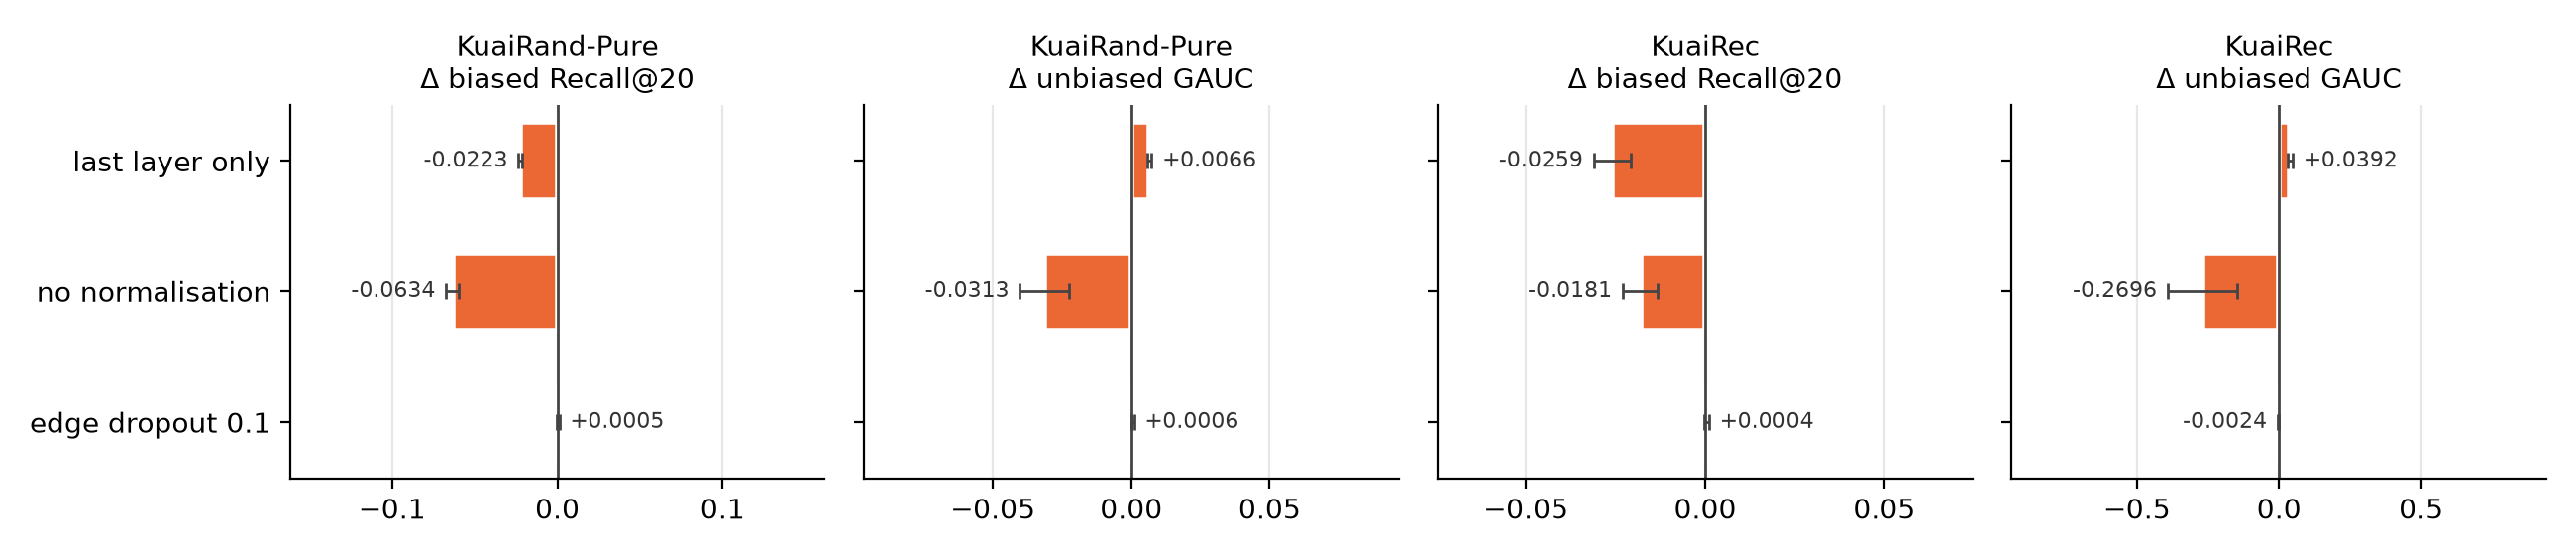

In [7]:
NAMES = {"last_layer": "last layer only", "no_norm": "no normalisation", "edge_drop": "edge dropout 0.1"}
PANELS = [("recall", "Δ biased Recall@20"), ("gauc", "Δ unbiased GAUC")]
fig, axes = plt.subplots(1, 4, figsize=(13, 2.8), sharey=True)
for ax, (name, (metric, title)) in zip(axes, [(n, p) for n in DATASETS for p in PANELS]):
    d = deltas[(deltas.dataset == name) & (deltas.metric == HEADLINE[metric])].set_index("variant").loc[list(ABLATIONS)]
    y = np.arange(len(d))[::-1]
    ax.barh(y, d.delta, xerr=d["std"], height=0.6, color="#eb6834", edgecolor="white", linewidth=2, capsize=3,
            error_kw=dict(lw=1, ecolor="#444"))
    lim = (d.delta.abs() + d["std"]).max() * 2.4
    for yi, val, s in zip(y, d.delta, d["std"]):
        ax.text(val + np.sign(val or 1) * (s + lim * 0.04), yi, f"{val:+.4f}", va="center",
                ha="left" if val >= 0 else "right", fontsize=8, color="#333")
    ax.axvline(0, color="#444", lw=1)
    ax.set_xlim(-lim, lim)
    ax.locator_params(axis="x", nbins=5)
    ax.set_yticks(y, [NAMES[v] for v in d.index])
    ax.set_title(f"{LABELS[name]}\n{title}", fontsize=10)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="x", alpha=0.3)
    ax.set_axisbelow(True)
fig.tight_layout()
savefig(fig, "05_ablation.png")
plt.close(fig)  # display the saved file instead: the inline copy would embed matplotlib's web address
Image(filename=os.path.join(RESULTS_DIR, "05_ablation.png"))

In [8]:
out = dict(
    settings=dict(baseline=SELECTED, ablations=ABLATIONS, seeds=SEEDS, eval_every=5, patience=4,
                  std="sample (ddof=1) over seeds", noise_rule="paired t-test over seeds, within noise unless p < 0.05"),
    runs=df.to_dict("records"),
    summary=summary.reset_index().to_dict("records"),
    deltas=deltas.to_dict("records"),
)
print(save_json(json.loads(json.dumps(out, default=str)), "05_ablation.json"))

/Users/synthesislaptop1/Documents/NTU_SC4020_Project1/graph-recsys-exposure-bias/results/05_ablation.json


## Findings

Deltas are variant minus baseline, mean ± std over 3 seeds; p from a paired t-test. Most-popular's unbiased GAUC (notebook 06, seed 0) is 0.583 on KuaiRand-Pure and 0.761 on KuaiRec, for reference.

1. **Edge dropout (0.1) changes nothing measurable.** Every delta is within noise on both datasets and both tests (biased Recall@20 +0.0005 / +0.0004, unbiased GAUC +0.0006 / −0.0024, all p > 0.13). At this rate it neither regularises nor hurts; the selected models still improve up to the 100-epoch cap, so there is no overfitting for it to correct.

2. **The layer mean wins on the biased test and loses on the unbiased test.** Using only the last layer costs biased Recall@20 −0.022 (−10%) on KuaiRand-Pure and −0.026 (−20%) on KuaiRec (p ≤ 0.013). It also concentrates the recommendations: coverage falls from 0.50 to 0.12 (KuaiRand-Pure) and from 0.25 to 0.02 (KuaiRec), and their mean training degree rises from 914 to 1,139 and from 650 to 830. This is over-smoothing: after three propagation steps the embeddings converge towards the high-degree items, while the mean keeps layer 0, each node's own embedding. Yet on the unbiased test the last-layer model is *better*: GAUC +0.007 on KuaiRand-Pure (0.615 → 0.621, p = 0.004) and +0.039 on KuaiRec (0.736 → 0.775, p = 0.016; NDCG@5 +0.11), which lifts LightGCN above most-popular on KuaiRec (0.761). KuaiRec's unbiased block consists of popular videos, so the closer a model collapses to popularity, the better it scores there. The same component gets opposite verdicts from the two tests, so a design chosen on biased data can be the wrong choice for unbiased performance. Training of this variant is also less stable on KuaiRec (best epoch 5–75 across seeds).

3. **Symmetric normalisation is essential.** Without it, biased Recall@20 drops by −0.063 (−29%) on KuaiRand-Pure and −0.018 (−14%) on KuaiRec, and training stops early (best epoch about 30 instead of about 100). On the unbiased test, KuaiRand-Pure's GAUC falls to 0.583, exactly most-popular's level, and KuaiRec's collapses to 0.466 ± 0.122 (per seed 0.547, 0.325, 0.526): worse than random on average. The t-test calls the KuaiRec unbiased drop "within noise" only because the seeds disagree on its size; all three seeds are far below the baseline. Unnormalised propagation multiplies embeddings by node degrees at every layer, so scores follow item degree and training becomes unstable and seed-dependent.

4. **Full ranking cannot separate the variants on KuaiRand-Pure's unbiased test.** Its Recall@20 and NDCG@20 move by at most 0.0004 for every variant, including the broken unnormalised one, while GAUC separates them clearly. This supports the exposure-only protocol (GAUC, NDCG@5) as the unbiased headline.

**For the report:** normalisation is the component LightGCN cannot do without; the layer mean is what makes it accurate on the biased test, but partly by holding back the popularity collapse that the unbiased KuaiRec test rewards; edge dropout is unnecessary at this budget. Numbers: `results/05_ablation.json`, figure: `results/05_ablation.png`.